# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 15.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Єдинець Євген'
LIST_NUMBER = 6
assert STUDENT_NAME and LIST_NUMBER > 0
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print(f'Студент: {STUDENT_NAME}, ШІ-31; варіант {VARIANT}; файл {DATA}')

Студент: Єдинець Євген, ШІ-31; варіант 6; файл lr6_варіант_06.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap', 'scipy']
MODNAME = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Потрібні бібліотеки доступні')

Потрібні бібліотеки доступні



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# Бінарна класифікація: ціль відтік ∈ {0, 1}.
TYPE_OF_TASK = 'класифікація'
# AUC оцінює ранжування ризику для обох класів і не залежить від порога;
# accuracy може бути високою навіть для тривіальної відповіді «ніхто не піде».
METRIC = 'AUC'
# Стратифікація зберігає частку відтоку у згортках; повтори показують розкид.
CV_SCHEME = 'повторна стратифікована 5-кратна, 4 повтори'
for nme, val in [('TYPE_OF_TASK',TYPE_OF_TASK),('METRIC',METRIC),('CV_SCHEME',CV_SCHEME)]:
    assert val, 'Не заповнено: ' + nme
print('Рішення до перегляду даних зафіксовано:', TYPE_OF_TASK, METRIC, CV_SCHEME)

Рішення до перегляду даних зафіксовано: класифікація AUC повторна стратифікована 5-кратна, 4 повтори


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.286

типи стовпців: {'str': 13, 'float64': 8, 'int64': 5}


In [6]:
profile = pd.DataFrame([{
    'стовпець': c,
    'тип': str(raw[c].dtype),
    'унікальних': raw[c].nunique(dropna=True),
    '% пропусків': round(raw[c].isna().mean() * 100, 1),
    'приклад': str(raw[c].dropna().iloc[0]) if raw[c].notna().any() else '—'
} for c in raw.columns]).sort_values('% пропусків', ascending=False)
display(profile)
print('Колонок типу object:', (raw.dtypes == 'object').sum())
print('Accuracy прогнозу «ніхто не піде»: %.2f%%' % (100 * (1-raw[TARGET].mean())))

,стовпець,тип,унікальних,% пропусків,приклад
23,сума_повернення_депозиту,float64,341,71.4,100.25
22,дата_розірвання,str,286,71.4,2025-04-07
17,середній_час_відповіді_хв,float64,263,33.3,13.2
14,трафік_ГБ,str,982,5.0,146.0
12,щомісячний_платіж,str,1128,4.0,306.12
16,аварій_на_ділянці_за_квартал,float64,5,3.0,1.0
0,id_клієнта,str,1200,0.0,K60000
24,оцінка_ризику_менеджером,float64,5,0.0,5.0
21,дата_підключення,str,582,0.0,2024-11-03
20,скоринг_партнера,float64,1200,0.0,595.788


Колонок типу object: 0
Accuracy прогнозу «ніхто не піде»: 71.42%


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# 1) Написи з валютою замість числа.
print('Нечислові записи платежу:')
print(raw.loc[raw['щомісячний_платіж'].astype('string').str.contains('грн', na=False),
              'щомісячний_платіж'].head(5).to_list())
# 2) Справжнє числове значення трафіку пошкоджене Excel і записане ISO-датою.
print('Дати Excel у трафіку:')
print(raw.loc[raw['трафік_ГБ'].astype('string').str.contains('1900-', na=False),
              'трафік_ГБ'].to_list())
# 3) Пропуск оцінки швидкості підтримки залежить від наявності звернень.
print('Пропуск часу відповіді за кількістю звернень:')
display(pd.crosstab(raw['кількість_звернень_у_підтримку'] == 0,
                    raw['середній_час_відповіді_хв'].isna(),
                    margins=True))

Нечислові записи платежу:
['277.16 грн', '298.44 грн', '676.6 грн', '305.51 грн', '378.78 грн']
Дати Excel у трафіку:
['1900-01-24 00:00:00', '1900-01-10 00:00:00', '1900-01-09 00:00:00']
Пропуск часу відповіді за кількістю звернень:


середній_час_відповіді_хв,False,True,All
кількість_звернень_у_підтримку,,,
False,800,0,800
True,0,400,400
All,800,400,1200


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE = 'трафік_ГБ'
PROBLEM_MNAR = 'середній_час_відповіді_хв'
MNAR_MEANING = ('У клієнтів без звернень до підтримки часу відповіді не існує; '
                'пропуск описує відсутність контакту, а не випадкову втрату вимірювання.')
for nme, val in [('PROBLEM_TEXT_IN_NUMBER',PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE',PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR',PROBLEM_MNAR),('MNAR_MEANING',MNAR_MEANING)]:
    assert val, nme
assert all(c in raw.columns for c in [PROBLEM_TEXT_IN_NUMBER, PROBLEM_EXCEL_DATE, PROBLEM_MNAR])
print('Проблеми визначено: текст, Excel-дата, змістовий пропуск')

Проблеми визначено: текст, Excel-дата, змістовий пропуск


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    '''Безпечний розбір чисел; Excel-дати не є числами.'''
    def one(v):
        if v is None or pd.isna(v):
            return np.nan
        if isinstance(v, (pd.Timestamp, datetime.datetime, datetime.date, np.datetime64)):
            return np.nan
        if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, (bool,np.bool_)):
            return float(v)
        t = str(v).strip()
        # Excel замінив число клітинкою з датою; відновлювати день місяця як число не можна.
        if re.match(r'^\d{4}[-/]\d{1,2}[-/]\d{1,2}(?:\s|$)', t):
            return np.nan
        m = re.search(r'[-+]?(?:\d+(?:[.,]\d*)?|[.,]\d+)', t.replace('\u00a0',' '))
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one).astype(float)

_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає', '1900-01-11 00:00:00'])
_r = to_number(_t)
assert _r.iloc[0] == 1 and abs(_r.iloc[1]-350.5)<1e-9 and abs(_r.iloc[2]-2.75)<1e-9
assert _r.iloc[3:].isna().all(), 'Дати Excel і пропуски мають залишатися NaN'
print('to_number: усі тести пройдено')

to_number: усі тести пройдено


In [10]:
DROP_ALWAYS = ['id_клієнта']  # Технічний ключ, неприпустимо вчити на ID.

def build_X(d, drop):
    '''Схема колонок без навчання параметрів: всі fit — тільки в Pipeline.'''
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        v = d[c]
        if c in ('дата_підключення', 'дата_розірвання'):
            # Дата розірвання потрібна ТІЛЬКИ у демонстраційному витікному X_all.
            dt = pd.to_datetime(v, errors='coerce')
            X[c] = ((dt - pd.Timestamp('1970-01-01')).dt.days).astype(float)
            kind = 'календарний день як число'
        elif pd.api.types.is_numeric_dtype(v):
            X[c] = pd.to_numeric(v, errors='coerce').astype(float)
            kind = 'число'
        else:
            parsed = to_number(v)
            usable = v.notna().sum()
            ratio = parsed.notna().sum() / max(usable, 1)
            if ratio > 0.80 and c not in ('стать', 'філія', 'код_тарифного_плану'):
                X[c] = parsed
                kind = f'число з тексту ({ratio:.0%})'
            else:
                clean = v.astype('string').str.strip().str.lower()
                if c == 'стать':
                    clean = clean.replace({'ч':'чоловік', 'чол':'чоловік',
                                            'ж':'жінка','жін':'жінка'})
                X[c] = clean.astype('category')
                kind = 'категорія'
        log.append({'стовпець':c, 'рішення':kind,
                    'пропуски після':int(X[c].isna().sum())})
    return X, pd.DataFrame(log)

X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
assert len(X_all)==len(raw) and 'дата_підключення' in X_all
print('матриця ознак:', X_all.shape)
print('категоріальних:',len(X_all.select_dtypes(include='category').columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення,пропуски після
0,вік,число,0
1,стать,категорія,0
2,місто,категорія,0
3,філія,категорія,0
4,тариф,категорія,0
5,тип_підключення,категорія,0
6,спосіб_оплати,категорія,0
7,автоплатіж,категорія,0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num = X.select_dtypes(include='number').columns.tolist()
    cat = X.select_dtypes(include=['category', 'object', 'string']).columns.tolist()
    transformers = []
    if num:
        transformers.append(('num', Pipeline([
            ('impute',SimpleImputer(strategy='median', add_indicator=True)),
            ('scale',StandardScaler())]), num))
    if cat:
        transformers.append(('cat', Pipeline([
            ('impute',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat))
    return Pipeline([('prep',ColumnTransformer(transformers, sparse_threshold=0)),
                     ('clf',clf)])

def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)
_p = make_pipe(X_all, logreg())
_s = cross_val_score(_p,X_all,y,cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=1,random_state=SEED),scoring='roc_auc')
assert len(_s)==5
print('Конвеєр + тестовий CV: AUC %.3f' % _s.mean())

Конвеєр + тестовий CV: AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0=time.perf_counter()
auc_naive=cross_val_score(make_pipe(X_all,logreg()), X_all, y, cv=cv, scoring='roc_auc')
time_naive=time.perf_counter()-t0
print('Ознак:',X_all.shape[1],'; некоректний AUC: %.4f ± %.4f' % (auc_naive.mean(),auc_naive.std()))
print('Час 20 запусків: %.1f c' % time_naive)

Ознак: 24 ; некоректний AUC: 1.0000 ± 0.0000
Час 20 запусків: 0.3 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = (f'AUC {auc_naive.mean():.3f} є підозріло високою для прогнозу відтоку; '
                  'у CRM-вивантаженні, найімовірніше, присутні післяподієві поля з цільовим витоком.')
assert FIRST_REACTION
print(FIRST_REACTION)

AUC 1.000 є підозріло високою для прогнозу відтоку; у CRM-вивантаженні, найімовірніше, присутні післяподієві поля з цільовим витоком.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    '''AUC факту заповненості; захист від малочисельних груп і обох напрямів зв'язку.'''
    rows=[]
    for c in d.columns:
        if c==TARGET:
            continue
        observed=d[c].notna().astype(int)
        n_ok=int(observed.sum()); n_nan=len(observed)-n_ok
        if min(n_ok,n_nan)<min_group:
            continue
        auc=roc_auc_score(y,observed)
        rows.append({'ознака':c,'заповнено':n_ok,
                     'частка_відтоку_де_заповнено':float(y[observed==1].mean()),
                     'частка_відтоку_де_пропуск':float(y[observed==0].mean()),
                     'показник':max(float(auc),float(1-auc))})
    return pd.DataFrame(rows).sort_values('показник',ascending=False).reset_index(drop=True)
scan=leak_scan(raw,y,min_group=20)
assert not scan.empty
print('Детектор перевіряє тільки заповненість, не значення колонки')
display(scan)

Детектор перевіряє тільки заповненість, не значення колонки


,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
0,дата_розірвання,343,1.000000,0.000000,1.000000
1,сума_повернення_депозиту,343,1.000000,0.000000,1.000000
2,середній_час_відповіді_хв,800,0.320000,0.217500,0.555792
3,трафік_ГБ,1140,0.291228,0.183333,0.512553
4,щомісячний_платіж,1152,0.281250,0.395833,0.510777
5,аварій_на_ділянці_за_квартал,1164,0.289519,0.166667,0.508757


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'дата_розірвання',              # З'являється лише після розірвання договору.
    'сума_повернення_депозиту'      # Обчислюється при закритті договору.
]
assert len(TARGET_LEAK)>=2 and all(c in raw.columns for c in TARGET_LEAK)
print('Цільовий витік:',TARGET_LEAK)

Цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.975 ± 0.008


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = ['оцінка_ризику_менеджером']
HUMAN_LEAK_WHY = ('Оцінку менеджер записав ретроспективно, вже бачачи поведінку клієнта і результат; '
                  'вона заповнена для всіх клієнтів, тому детектор за фактом пропусків її не виявляє.')
assert len(HUMAN_LEAK)>=1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3,_=build_X(raw, DROP_ALWAYS+TARGET_LEAK+HUMAN_LEAK)
auc3=cross_val_score(make_pipe(X3,logreg()),X3,y,cv=cv,scoring='roc_auc')
print('Після вилучення оцінок менеджера: %d ознак; AUC %.4f ± %.4f' %
      (X3.shape[1],auc3.mean(),auc3.std()))

Після вилучення оцінок менеджера: 21 ознак; AUC 0.8298 ± 0.0221


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

Частка відтоку за філіями:


,клієнтів,"відтік, осіб",частка
філія,,,
Ф-06 Приміська,213,55,0.258216
Ф-03 Схід,170,45,0.264706
Ф-01 Центр,233,64,0.274678
Ф-04 Південь,194,57,0.293814
Ф-02 Захід,186,55,0.295699
Ф-05 Північ,204,67,0.328431


Частка відтоку за кварталами підключення:


,клієнтів,"відтік, осіб",частка
дата_підключення,,,
2023Q1,146,26,0.178082
2023Q2,127,28,0.220472
2023Q3,155,33,0.212903
2023Q4,178,41,0.230337
2024Q1,146,32,0.219178
2024Q2,166,67,0.403614
2024Q3,132,52,0.393939
2024Q4,150,64,0.426667


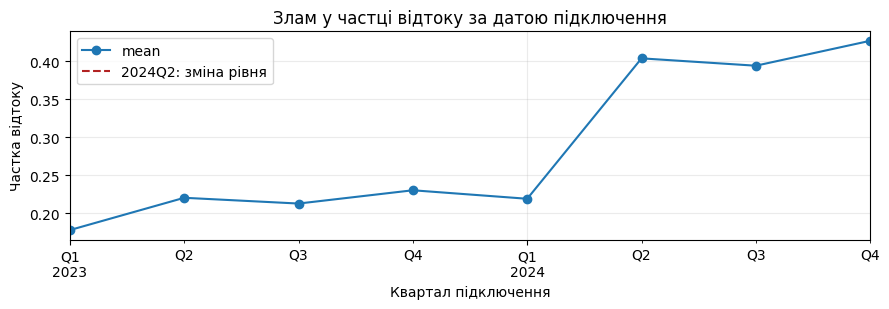

In [19]:
branch_rates=raw.groupby('філія')['відтік'].agg(['size','sum','mean']).sort_values('mean')
quarter=pd.to_datetime(raw['дата_підключення']).dt.to_period('Q')
quarter_rates=raw.groupby(quarter)['відтік'].agg(['size','sum','mean']).sort_index()
print('Частка відтоку за філіями:')
display(branch_rates.rename(columns={'size':'клієнтів','sum':'відтік, осіб','mean':'частка'}))
print('Частка відтоку за кварталами підключення:')
display(quarter_rates.rename(columns={'size':'клієнтів','sum':'відтік, осіб','mean':'частка'}))
fig, ax=plt.subplots(figsize=(9,3.2))
quarter_rates['mean'].plot(ax=ax, marker='o')
ax.axvline(4, color='firebrick',linestyle='--',label='2024Q2: зміна рівня')
ax.set(xlabel='Квартал підключення',ylabel='Частка відтоку',title='Злам у частці відтоку за датою підключення')
ax.legend();ax.grid(alpha=.25);plt.tight_layout();plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT='дата_підключення'
BREAK_DATE=pd.Timestamp('2024-04-01')
source=(pd.to_datetime(raw[SUSPECT])>=BREAK_DATE).astype(int)
print('Джерело: період підключення 2024-04-01 і пізніше; частка',source.mean())
X4,_=build_X(raw, DROP_ALWAYS+TARGET_LEAK+HUMAN_LEAK+[SUSPECT])
auc_src=cross_val_score(make_pipe(X4,logreg()),X4,source,cv=cv,scoring='roc_auc')
auc4=cross_val_score(make_pipe(X4,logreg()),X4,y,cv=cv,scoring='roc_auc')
print('AUC передбачення джерела: %.4f ± %.4f' %(auc_src.mean(),auc_src.std()))
print('AUC передбачення відтоку:  %.4f ± %.4f' %(auc4.mean(),auc4.std()))

Джерело: період підключення 2024-04-01 і пізніше; частка 0.37333333333333335
AUC передбачення джерела: 0.7511 ± 0.0221
AUC передбачення відтоку:  0.8135 ± 0.0216


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.975
3. мінус оцінки людини,21,0.830
4. мінус артефакт збору,20,0.814


чесне число: 0.814 ± 0.022


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT='викинути'
DECISION_WHY=('Для перенесення моделі між періодами слід вилучити дату підключення, '
              'яка кодує різкий злам обліку з 2024Q2; це консервативна оцінка, '
              'хоча частина сигналу дати може бути реальною. '
              'У модельних даних залишаються проксі періоду, тому повної незалежності не гарантовано.')
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—',DECISION_WHY)

викинути — Для перенесення моделі між періодами слід вилучити дату підключення, яка кодує різкий злам обліку з 2024Q2; це консервативна оцінка, хоча частина сигналу дати може бути реальною. У модельних даних залишаються проксі періоду, тому повної незалежності не гарантовано.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier
MODELS={
 'логістична регресія':logreg(),
 'одне дерево':DecisionTreeClassifier(max_depth=6,min_samples_leaf=12,random_state=SEED),
 'випадковий ліс':RandomForestClassifier(n_estimators=120,min_samples_leaf=3,random_state=SEED,n_jobs=-1),
 'гістограмний бустинг':HistGradientBoostingClassifier(max_iter=110,max_leaf_nodes=15,
                          l2_regularization=1.0,random_state=SEED)
}
rows=[]
model_cv_scores={}
for name,clf in MODELS.items():
    start=time.perf_counter()
    a=cross_val_score(make_pipe(X4,clf),X4,y,cv=cv,scoring='roc_auc')
    duration=time.perf_counter()-start
    model_cv_scores[name]=a
    rows.append({'модель':name,'AUC':round(a.mean(),4),'±':round(a.std(),4),
                 '20 навчань, c':round(duration,2),
                 'оцінка с на 100 навчань':round(duration*5,1)})
cmp_models=pd.DataFrame(rows).set_index('модель')
display(cmp_models)
print('Час на 100 запусків — оцінка (помножено фактичний час 20 запусків на 5).')

,AUC,±,"20 навчань, c",оцінка с на 100 навчань
модель,,,,
логістична регресія,0.8135,0.0216,0.45,2.2
одне дерево,0.7454,0.0280,0.37,1.9
випадковий ліс,0.8289,0.0203,1.96,9.8
гістограмний бустинг,0.8229,0.0191,5.88,29.4


Час на 100 запусків — оцінка (помножено фактичний час 20 запусків на 5).


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy.stats import t as student_t

def paired(a,b):
    '''Середній парний приріст b-a та орієнтовна півширина 95% ДІ (20 згорток).'''
    d=np.asarray(b,dtype=float)-np.asarray(a,dtype=float)
    assert len(d)>1 and np.isfinite(d).all()
    return float(d.mean()),float(student_t.ppf(.975,len(d)-1)*d.std(ddof=1)/np.sqrt(len(d)))

base=model_cv_scores['логістична регресія']
model_diffs={}
for name in ['випадковий ліс','гістограмний бустинг']:
    other=model_cv_scores[name]
    m,h=paired(base,other)
    model_diffs[name]=(m,h)
    print('%s: приріст %+0.4f ± %.4f (95%% наближений ДІ); %s' %
          (name,m,h,'ДІ не містить 0' if abs(m)>h else 'ДІ містить 0'))
print('Примітка: повторні CV-згортки залежні, ці ДІ орієнтовні, а не незалежний зовнішній тест.')

випадковий ліс: приріст +0.0154 ± 0.0067 (95% наближений ДІ); ДІ не містить 0
гістограмний бустинг: приріст +0.0094 ± 0.0077 (95% наближений ДІ); ДІ не містить 0
Примітка: повторні CV-згортки залежні, ці ДІ орієнтовні, а не незалежний зовнішній тест.


In [25]:
CHOSEN_MODEL=max(MODELS,key=lambda k:float(model_cv_scores[k].mean()))
CHOSEN_WHY=(f'За AUC найбільше середнє має «{CHOSEN_MODEL}» '
            f'({model_cv_scores[CHOSEN_MODEL].mean():.3f}); враховуємо також '
            'простоту пояснення, обчислювальну вартість (порівняльна таблиця) '
            'і розкид між згортками. Для розділів 9–13 окремо досліджуємо випадковий ліс, '
            'щоб коректно порівняти impurity, permutation і TreeSHAP.')
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('Обрано:',CHOSEN_MODEL,'—',CHOSEN_WHY)

Обрано: випадковий ліс — За AUC найбільше середнє має «випадковий ліс» (0.829); враховуємо також простоту пояснення, обчислювальну вартість (порівняльна таблиця) і розкид між згортками. Для розділів 9–13 окремо досліджуємо випадковий ліс, щоб коректно порівняти impurity, permutation і TreeSHAP.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    F=X.copy()
    # Гіпотеза 1: висока ціна одиниці обіцяної швидкості посилює незадоволення.
    F['грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт'].replace(0,np.nan)
    # Гіпотеза 2: інтенсивність звернень важливіша за їх абсолютну кількість.
    F['звернення_на_рік'] = (F['кількість_звернень_у_підтримку'] * 12 /
                              F['місяців_обслуговування'].clip(lower=1))
    # Гіпотеза 3: аварії на місяць стажу — умовна інтенсивність проблем мережі.
    F['аварії_на_рік'] = (F['аварій_на_ділянці_за_квартал'] * 4 /
                          F['місяців_обслуговування'].clip(lower=1))
    # Гіпотеза 4: трафік на одну гривню дозволяє врахувати цінність тарифу.
    F['ГБ_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж'].replace(0,np.nan)
    return F
X5=add_features(X4)
assert X5.shape[1]>=X4.shape[1]+3
print('Ознак до:',len(X4.columns),'; після:',len(X5.columns))
print('Нові:',list(X5.columns.difference(X4.columns)))

Ознак до: 20 ; після: 24
Нові: ['ГБ_на_гривню', 'аварії_на_рік', 'грн_за_Мбіт', 'звернення_на_рік']


In [27]:
t0=time.perf_counter()
auc5=cross_val_score(make_pipe(X5,logreg()),X5,y,cv=cv,scoring='roc_auc')
feature_cv_time=time.perf_counter()-t0
feat_gain,feat_ci=paired(base,auc5)
print('AUC із новими ознаками: %.4f ± %.4f' %(auc5.mean(),auc5.std()))
print('Парний приріст: %+.4f ± %.4f, час 20 навчань %.2f c' %
      (feat_gain,feat_ci,feature_cv_time))

AUC із новими ознаками: 0.8092 ± 0.0222
Парний приріст: -0.0044 ± 0.0050, час 20 навчань 0.54 c


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
complex_name='випадковий ліс'
complex_gain,complex_ci=model_diffs[complex_name]
complex_time=float(cmp_models.loc[complex_name,'20 навчань, c'])
FEATURES_VS_MODEL=(
 f'Інженерія ознак: ΔAUC={feat_gain:+.4f} ± {feat_ci:.4f}, {feature_cv_time:.1f} с; '
 f'{complex_name}: ΔAUC={complex_gain:+.4f} ± {complex_ci:.4f}, {complex_time:.1f} с '
 '(20 запусків за однаковою CV). '
 + ('Більший виміряний приріст дали нові ознаки.' if feat_gain>complex_gain
    else 'Більший виміряний приріст дала складніша модель.')
 + ' Інтервали наведено як орієнтовні, без причинної інтерпретації.'
)
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Інженерія ознак: ΔAUC=-0.0044 ± 0.0050, 0.5 с; випадковий ліс: ΔAUC=+0.0154 ± 0.0067, 2.0 с (20 запусків за однаковою CV). Більший виміряний приріст дала складніша модель. Інтервали наведено як орієнтовні, без причинної інтерпретації.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X=X5
FINAL_CLF=RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=-1)
Xtr,Xte,ytr,yte=train_test_split(FINAL_X,y,test_size=.3,stratify=y,random_state=SEED)
model=make_pipe(FINAL_X, FINAL_CLF).fit(Xtr,ytr)
auc_hold=roc_auc_score(yte,model.predict_proba(Xte)[:,1])
print('Відкладено %d записів; ROC-AUC: %.4f' %(len(Xte),auc_hold))

Відкладено 360 записів; ROC-AUC: 0.8188


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,сумарна impurity важливість
вік,0.094410
код_тарифного_плану,0.085779
щомісячний_платіж,0.080629
місяців_обслуговування,0.069370
ГБ_на_гривню,0.069256
грн_за_Мбіт,0.057203
трафік_ГБ,0.052462
трафік_МБ,0.051880
звернення_на_рік,0.049807
середній_час_відповіді_хв,0.041802


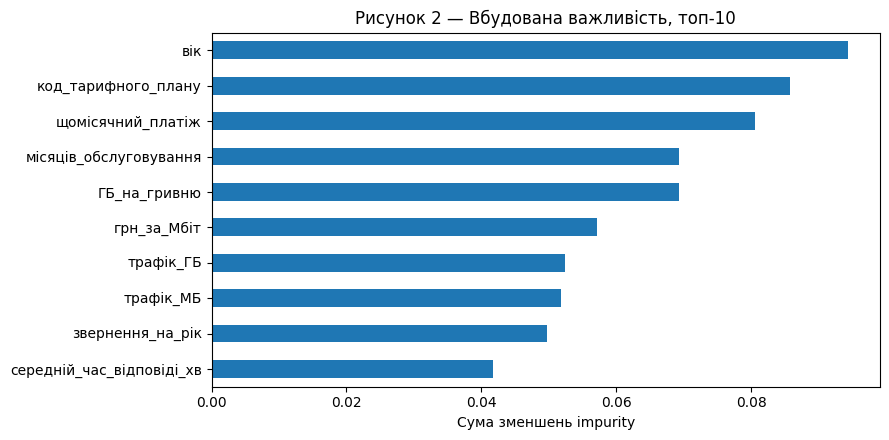

In [30]:
prep=model.named_steps['prep']; clf=model.named_steps['clf']
post_names=prep.get_feature_names_out()
num_cols=FINAL_X.select_dtypes(include='number').columns.tolist()
cat_cols=FINAL_X.select_dtypes(include=['category','object','string']).columns.tolist()
raw_imp=clf.feature_importances_
# ColumnTransformer порядок: числові, включно з індикаторами пропусків, далі дамі категорій.
num_t=prep.named_transformers_['num']
num_size=num_t.transform(FINAL_X[num_cols].head(2)).shape[1]
cat_ohe=prep.named_transformers_['cat'].named_steps['onehot']
cat_sizes=[len(v) for v in cat_ohe.categories_]
imp_dict=dict.fromkeys(FINAL_X.columns,0.0)
for i,raw_col in enumerate(num_cols):
    imp_dict[raw_col]+=float(raw_imp[i])
# Індикатори пропусків, які повернув SimpleImputer(add_indicator=True).
for j,num_idx in enumerate(num_t.named_steps['impute'].indicator_.features_):
    imp_dict[num_cols[num_idx]]+=float(raw_imp[len(num_cols)+j])
assert num_size==len(num_cols)+len(num_t.named_steps['impute'].indicator_.features_)
pos=num_size
for col,n in zip(cat_cols,cat_sizes):
    imp_dict[col]+=float(raw_imp[pos:pos+n].sum()); pos+=n
assert pos==len(raw_imp) and np.isclose(sum(imp_dict.values()),1)
gini_imp=pd.Series(imp_dict).sort_values(ascending=False)
display(gini_imp.head(10).to_frame('сумарна impurity важливість'))
fig,ax=plt.subplots(figsize=(9,4.5))
gini_imp.head(10).iloc[::-1].plot.barh(ax=ax)
ax.set(xlabel='Сума зменшень impurity',title='Рисунок 2 — Вбудована важливість, топ-10')
plt.tight_layout();plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.067697
щомісячний_платіж,0.028325
місяців_обслуговування,0.023261
ГБ_на_гривню,0.019640
звернення_на_рік,0.006524
швидкість_тарифу_Мбіт,0.005776
тип_підключення,0.002867
знижка_відсоток,0.002782
кількість_послуг,0.002148
грн_за_Мбіт,0.001978


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
importance_comparison=pd.DataFrame({'вбудована':gini_imp,
                                    'перестановочна ΔAUC':perm_imp}).sort_values('вбудована',ascending=False)
display(importance_comparison.round(5))
print('Топ-5 вбудованої важливості:',importance_comparison.head(5).index.to_list())

,вбудована,перестановочна ΔAUC
вік,0.09441,0.06770
код_тарифного_плану,0.08578,-0.00181
щомісячний_платіж,0.08063,0.02833
місяців_обслуговування,0.06937,0.02326
ГБ_на_гривню,0.06926,0.01964
грн_за_Мбіт,0.05720,0.00198
трафік_ГБ,0.05246,-0.00005
трафік_МБ,0.05188,0.00123
звернення_на_рік,0.04981,0.00652
середній_час_відповіді_хв,0.04180,-0.00321


Топ-5 вбудованої важливості: ['вік', 'код_тарифного_плану', 'щомісячний_платіж', 'місяців_обслуговування', 'ГБ_на_гривню']


In [33]:
# Код тарифу має 40 рівнів, тому MDI може переоцінити його корисність.
FAKE_IMPORTANT='код_тарифного_плану'
FAKE_IMPORTANT_WHY=('Код тарифного плану має 40 категорій. One-hot кодування дає деревам '
    'багато дамі-ознак і випадкових можливостей зменшити impurity на train, '
    'але перестановка вихідного стовпця на test оцінює реальну користь.')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
assert gini_imp.index.get_loc(FAKE_IMPORTANT)<5, 'Очікується топ-5 вбудованої важливості'
print('Шумна ознака:',FAKE_IMPORTANT,
      '; ранг impurity', int(gini_imp.index.get_loc(FAKE_IMPORTANT)+1),
      '; permutation ΔAUC',round(float(perm_imp[FAKE_IMPORTANT]),5))

Шумна ознака: код_тарифного_плану ; ранг impurity 2 ; permutation ΔAUC -0.00181


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
# Додаємо числові колонки після перевірки змісту, щоби не сплутати кореляцію із дублем.
corr=FINAL_X.select_dtypes(include='number').corr().abs()
upper=corr.where(np.triu(np.ones(corr.shape,dtype=bool),k=1))
strong_pairs=(upper.stack().rename('|r|').sort_values(ascending=False))
display(strong_pairs[strong_pairs>0.97].to_frame())

,,|r|
трафік_ГБ,трафік_МБ,0.999706


In [35]:
DUP_PAIR=['трафік_ГБ','трафік_МБ']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0]!=DUP_PAIR[1]
print('Абсолютна кореляція:',FINAL_X[DUP_PAIR].corr().iloc[0,1])
for c in DUP_PAIR:
    print('Повна модель: %-22s ΔAUC %+.5f' % (c,perm_imp[c]))
Xtr_wo=Xtr.drop(columns=DUP_PAIR[1]); Xte_wo=Xte.drop(columns=DUP_PAIR[1])
model_wo=make_pipe(Xtr_wo,RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=-1)).fit(Xtr_wo,ytr)
perm_wo=permutation_importance(model_wo,Xte_wo,yte,n_repeats=10,random_state=SEED,scoring='roc_auc')
imp_wo=pd.Series(perm_wo.importances_mean,index=Xte_wo.columns)
print('Без дубля: %-22s ΔAUC %+.5f' %(DUP_PAIR[0],imp_wo[DUP_PAIR[0]]))
print('AUC без дубля: %.4f; із дублем: %.4f' %
      (roc_auc_score(yte,model_wo.predict_proba(Xte_wo)[:,1]),auc_hold))

Абсолютна кореляція: 0.9997064417174792
Повна модель: трафік_ГБ              ΔAUC -0.00005
Повна модель: трафік_МБ              ΔAUC +0.00123
Без дубля: трафік_ГБ              ΔAUC +0.00749
AUC без дубля: 0.8237; із дублем: 0.8188


In [36]:
DUP_EXPLANATION=(f'Дві ознаки фактично є одним трафіком у ГБ і МБ (|r|={abs(FINAL_X[DUP_PAIR].corr().iloc[0,1]):.5f}). '
 f'У повному лісі permutation ΔAUC: {perm_imp[DUP_PAIR[0]]:+.4f} і {perm_imp[DUP_PAIR[1]]:+.4f}; '
 f'після видалення МБ важливість ГБ: {imp_wo[DUP_PAIR[0]]:+.4f}. '
 'Мала важливість одного дубля не означає відсутності інформації: її замінює другий.')
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Дві ознаки фактично є одним трафіком у ГБ і МБ (|r|=0.99971). У повному лісі permutation ΔAUC: -0.0000 і +0.0012; після видалення МБ важливість ГБ: +0.0075. Мала важливість одного дубля не означає відсутності інформації: її замінює другий.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

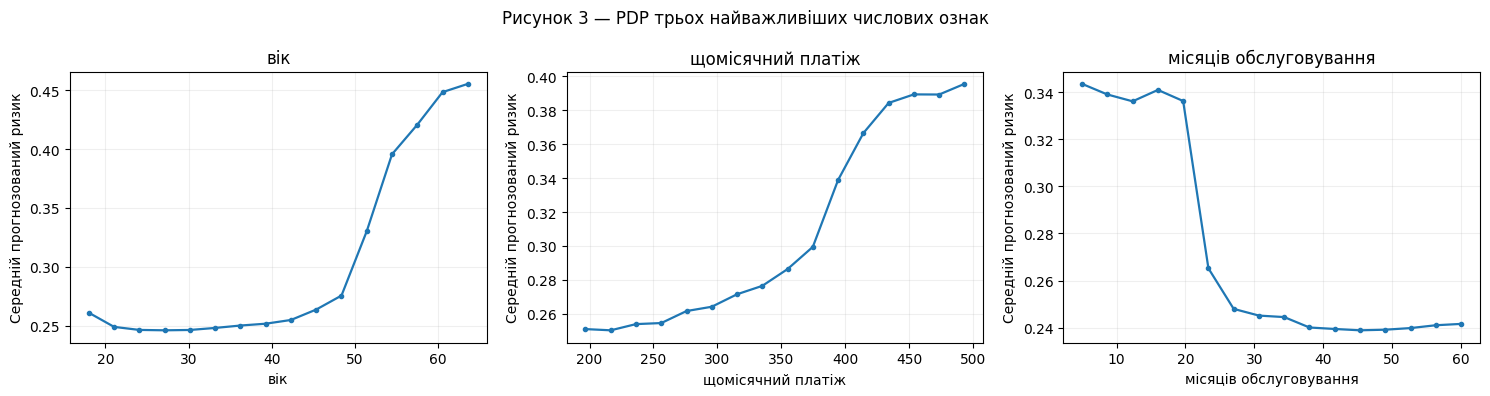

Використано підвибірки лише без NaN; три ознаки: ['вік', 'щомісячний_платіж', 'місяців_обслуговування']
вік : мінімум при 27.118 ; min/max ризику 0.246 / 0.455
щомісячний_платіж : мінімум при 216.603 ; min/max ризику 0.25 / 0.396
місяців_обслуговування : мінімум при 45.333 ; min/max ризику 0.239 / 0.343


In [37]:
from sklearn.inspection import PartialDependenceDisplay
# PDP на підвибірках з відомим значенням числової ознаки; без пропусків у сітці.
ranked_numeric = [c for c in perm_imp.sort_values(ascending=False).index
                  if c in FINAL_X.select_dtypes(include='number').columns]
TOP_PDP = ranked_numeric[:3]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
PDP_RESULT = {}
for col, ax in zip(TOP_PDP, axs):
    valid = FINAL_X.loc[FINAL_X[col].notna()]
    clean = valid.sample(n=min(500, len(valid)), random_state=SEED)
    r = partial_dependence(model, clean, [col], grid_resolution=16,
                           method='brute', kind='average')
    grid = np.asarray(r['grid_values'][0]); values = np.asarray(r['average'][0])
    PDP_RESULT[col] = (grid, values)
    ax.plot(grid, values, '-o', linewidth=1.6, markersize=3)
    ax.set(xlabel=col.replace('_',' '), ylabel='Середній прогнозований ризик', title=col.replace('_',' '))
    ax.grid(alpha=.2)
plt.suptitle('Рисунок 3 — PDP трьох найважливіших числових ознак')
plt.tight_layout();plt.show()
print('Використано підвибірки лише без NaN; три ознаки:', TOP_PDP)
for c,(grid,avg) in PDP_RESULT.items():
    print(c, ': мінімум при', round(float(grid[np.argmin(avg)]),3),
          '; min/max ризику', round(float(avg.min()),3), '/', round(float(avg.max()),3))

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

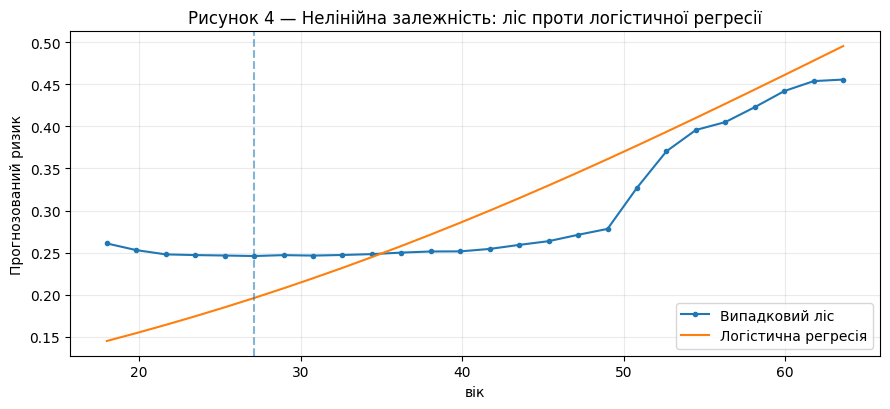

Мінімум PDP лісу: 27.12
Кінці / мінімум: 0.261 0.246 0.455


In [38]:
# Підбір немонотонної ознаки за формою PDP: внутрішній мінімум і два схили.
# У-подібний характер за віком: ризик має мінімум усередині шкали.
NONLINEAR_FEATURE='вік'
assert NONLINEAR_FEATURE in FINAL_X.columns
clean=FINAL_X.loc[FINAL_X[NONLINEAR_FEATURE].notna()].sample(n=500,random_state=SEED)
forest_pd=partial_dependence(model,clean,[NONLINEAR_FEATURE],grid_resolution=26,method='brute')
logfit=make_pipe(Xtr,logreg()).fit(Xtr,ytr)
linear_pd=partial_dependence(logfit,clean,[NONLINEAR_FEATURE],grid_resolution=26,method='brute')
pdp_grid=np.asarray(forest_pd['grid_values'][0]); pdp_y=np.asarray(forest_pd['average'][0]);
fig,ax=plt.subplots(figsize=(9,4.2))
ax.plot(pdp_grid,pdp_y,label='Випадковий ліс',marker='o',ms=3)
ax.plot(linear_pd['grid_values'][0],np.asarray(linear_pd['average'])[0],label='Логістична регресія')
ax.axvline(pdp_grid[np.argmin(pdp_y)],linestyle='--',alpha=.55)
ax.set(xlabel=NONLINEAR_FEATURE,ylabel='Прогнозований ризик',
       title='Рисунок 4 — Нелінійна залежність: ліс проти логістичної регресії')
ax.legend();ax.grid(alpha=.25);plt.tight_layout();plt.show()
print('Мінімум PDP лісу:',round(float(pdp_grid[np.argmin(pdp_y)]),2))
print('Кінці / мінімум:',round(float(pdp_y[0]),3),round(float(pdp_y.min()),3),round(float(pdp_y[-1]),3))

In [39]:
NONLINEAR_MEANING=('Прогнозований ризик залежить від віку нелінійно: '
                   'у середній віковій групі він менший, а у молодших і старших клієнтів зростає; '
                   'це асоціація у даних, а не доказ причинності.')
NONLINEAR_FIX='Квадрат відхилення віку від значення мінімуму PDP'
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING,'\n',NONLINEAR_FIX)

Прогнозований ризик залежить від віку нелінійно: у середній віковій групі він менший, а у молодших і старших клієнтів зростає; це асоціація у даних, а не доказ причинності. 
 Квадрат відхилення віку від значення мінімуму PDP


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
quad_center=float(pdp_grid[np.argmin(pdp_y)])
quad_col='квадрат_відхилення_віку'
Xquad=FINAL_X.copy()
Xquad[quad_col]=(Xquad[NONLINEAR_FEATURE]-quad_center)**2
# Однакова схема і згортки, однакові базові ознаки.
quad_baseline=cross_val_score(make_pipe(FINAL_X,logreg()),FINAL_X,y,cv=cv,scoring='roc_auc')
quad_scores=cross_val_score(make_pipe(Xquad,logreg()),Xquad,y,cv=cv,scoring='roc_auc')
quad_delta,quad_ci=paired(quad_baseline,quad_scores)
print('Центр квадрата %.2f років; AUC без %.4f, з %.4f; Δ %.4f ± %.4f' %
      (quad_center,quad_baseline.mean(),quad_scores.mean(),quad_delta,quad_ci))

Центр квадрата 27.12 років; AUC без 0.8092, з 0.8268; Δ 0.0176 ± 0.0048


In [41]:
QUAD_GAIN=float(quad_delta)
assert QUAD_GAIN is not None
print('Приріст від квадратної ознаки: %+.4f (95%% орієнтовний ДІ ± %.4f)' % (QUAD_GAIN,quad_ci))

Приріст від квадратної ознаки: +0.0176 (95% орієнтовний ДІ ± 0.0048)


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

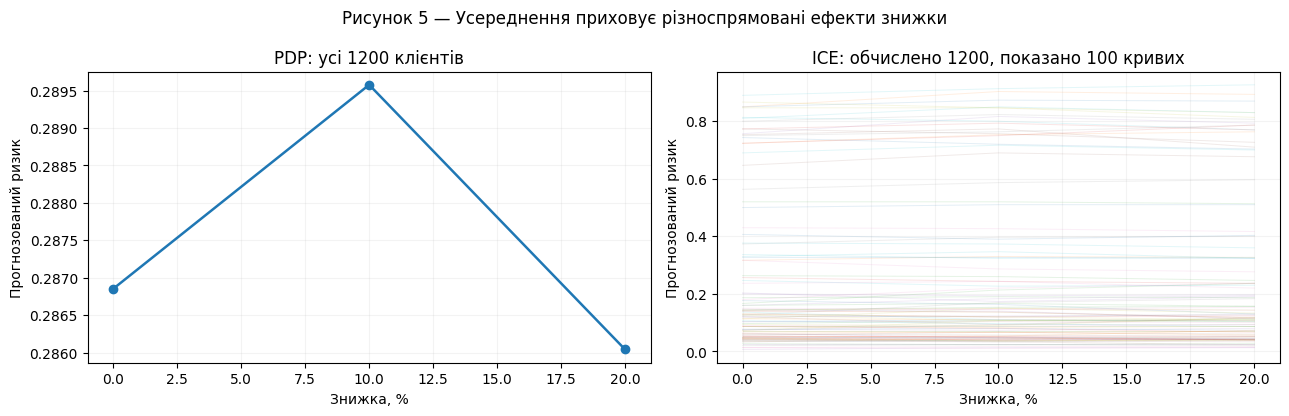

ICE: повна матриця (1200, 3) ; зміна середнього ризику 0%→20%: -0.00081


In [42]:
# PDP і ICE обчислюємо на всій матриці (1200 клієнтів).
# Для читабельності візуалізуємо 100 випадкових із 1200 ICE-кривих.
discount_pd = partial_dependence(model, FINAL_X, ['знижка_відсоток'],
                                 kind='both', method='brute', grid_resolution=3)
discount_grid = np.asarray(discount_pd['grid_values'][0])
discount_mean = np.asarray(discount_pd['average'][0])
dice_all = np.asarray(discount_pd['individual'][0])
assert dice_all.shape[0] == len(FINAL_X)
dice_rng = np.random.default_rng(SEED)
draw_idx = dice_rng.choice(len(FINAL_X), size=min(100,len(FINAL_X)), replace=False)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].plot(discount_grid, discount_mean, '-o', linewidth=1.8)
for k in draw_idx:
    axs[1].plot(discount_grid, dice_all[k], linewidth=.7, alpha=.12)
axs[0].set_title('PDP: усі 1200 клієнтів')
axs[1].set_title('ICE: обчислено 1200, показано 100 кривих')
for ax in axs:
    ax.set(xlabel='Знижка, %', ylabel='Прогнозований ризик')
    ax.grid(alpha=.15)
plt.suptitle('Рисунок 5 — Усереднення приховує різноспрямовані ефекти знижки')
plt.tight_layout();plt.show()
print('ICE: повна матриця',dice_all.shape,'; зміна середнього ризику 0%→20%:',
      round(float(discount_mean[-1]-discount_mean[0]),5))

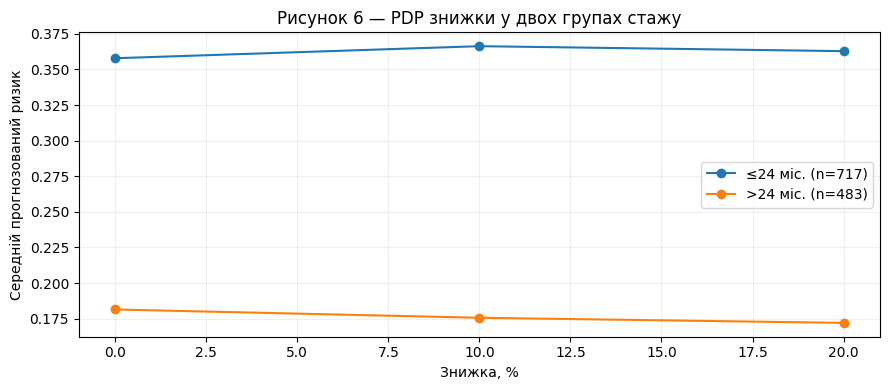

In [43]:
young=FINAL_X['місяців_обслуговування']<=24
fig,ax=plt.subplots(figsize=(9,4))
DISCOUNT_PDP={}
for label,mask in [('≤24 міс.',young),('>24 міс.',~young)]:
    r=partial_dependence(model,FINAL_X.loc[mask],['знижка_відсоток'],
                         kind='average',grid_resolution=3,method='brute')
    xvals=np.asarray(r['grid_values'][0],dtype=float)
    yvals=np.asarray(r['average'][0],dtype=float)
    ax.plot(xvals,yvals,'-o',label=f'{label} (n={mask.sum()})')
    DISCOUNT_PDP[label]=yvals
ax.set(xlabel='Знижка, %',ylabel='Середній прогнозований ризик',
       title='Рисунок 6 — PDP знижки у двох групах стажу')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
emp=raw.copy()
emp['група_стажу']=np.where(emp['місяців_обслуговування']<=24,'≤24 міс.','>24 міс.')
emp_rates=emp.groupby(['група_стажу','знижка_відсоток'])['відтік'].agg(
    ['sum','count','mean']).reset_index()
display(emp_rates.rename(columns={'sum':'пішли','count':'клієнтів','mean':'частка відтоку'}))

,група_стажу,знижка_відсоток,пішли,клієнтів,частка відтоку
0,>24 міс.,0,40,189,0.211640
1,>24 міс.,10,23,167,0.137725
2,>24 міс.,20,9,127,0.070866
3,≤24 міс.,0,91,307,0.296417
4,≤24 міс.,10,93,220,0.422727
5,≤24 міс.,20,87,190,0.457895


In [45]:
short=emp_rates.loc[emp_rates['група_стажу']=='≤24 міс.'].sort_values('знижка_відсоток')
long=emp_rates.loc[emp_rates['група_стажу']=='>24 міс.'].sort_values('знижка_відсоток')
INTERACTION_FOUND=(f'За емпіричними даними серед клієнтів зі стажем ≤24 міс. '
 f'відтік від 0% до 20% знижки змінюється з {short.iloc[0]["mean"]:.1%} до {short.iloc[-1]["mean"]:.1%}; '
 f'для >24 міс. — з {long.iloc[0]["mean"]:.1%} до {long.iloc[-1]["mean"]:.1%}. '
 'Середній PDP майже плаский. Підгрупові PDP мають слабкі різноспрямовані нахили, '
 'але для короткого стажу ліс недооцінює силу залежності в сирій таблиці; це обмеження моделі.')
BUSINESS_ACTION=('Для короткострокових та довгострокових клієнтів потрібна окрема перевірка '
                 'ефективності знижок (наприклад A/B-тест); спостережний зв’язок не доводить '
                 'що саме знижка спричиняє відтік або утримання.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND,'\n',BUSINESS_ACTION)

За емпіричними даними серед клієнтів зі стажем ≤24 міс. відтік від 0% до 20% знижки змінюється з 29.6% до 45.8%; для >24 міс. — з 21.2% до 7.1%. Середній PDP майже плаский. Підгрупові PDP мають слабкі різноспрямовані нахили, але для короткого стажу ліс недооцінює силу залежності в сирій таблиці; це обмеження моделі. 
 Для короткострокових та довгострокових клієнтів потрібна окрема перевірка ефективності знижок (наприклад A/B-тест); спостережний зв’язок не доводить що саме знижка спричиняє відтік або утримання.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap
prep=model.named_steps['prep']; clf=model.named_steps['clf']
Xte_t=np.asarray(prep.transform(Xte),dtype=float)
feat_names=prep.get_feature_names_out()
SAMPLE=min(360,Xte_t.shape[0])
expl=shap.TreeExplainer(clf)
sv=expl.shap_values(Xte_t[:SAMPLE])
if isinstance(sv, list):
    sv1=np.asarray(sv[1])  # сумісність зі старішими SHAP
else:
    sv1=sv[...,1] if np.ndim(sv)==3 else sv
assert sv1.shape == Xte_t[:SAMPLE].shape
expval=np.asarray(expl.expected_value)[1]
additivity_err=np.max(np.abs(expval+sv1.sum(axis=1)-clf.predict_proba(Xte_t[:SAMPLE])[:,1]))
print('SHAP',sv1.shape,'; макс. помилка адитивності',round(float(additivity_err),10))

SHAP (360, 89) ; макс. помилка адитивності 0.0


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

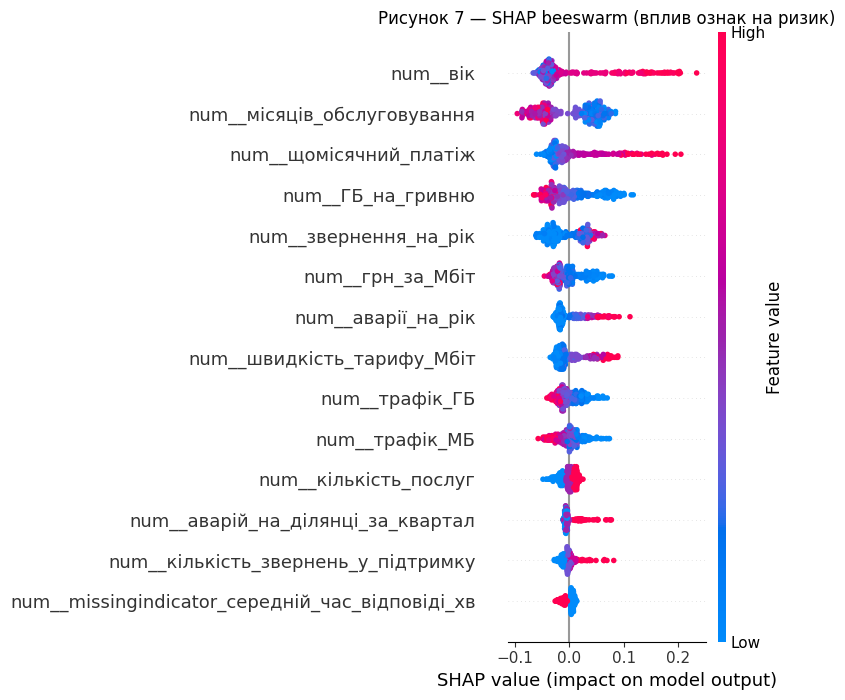

In [47]:
shap.summary_plot(sv1,Xte_t[:SAMPLE],feature_names=feat_names,
                  max_display=14,show=False)
plt.title('Рисунок 7 — SHAP beeswarm (вплив ознак на ризик)')
plt.tight_layout();plt.show()

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
# SHAP обчислено для всієї відкладеної частини; обираємо найбільший ризик серед усіх.
ranked_risk=model.predict_proba(Xte.iloc[:SAMPLE])[:,1]
idx=int(np.argmax(ranked_risk))
client_original=Xte.iloc[idx]
client_contrib=pd.Series(sv1[idx],index=feat_names)
large=client_contrib.abs().sort_values(ascending=False).head(3).index
client_top3=client_contrib.loc[large]
print('Клієнт:',raw.loc[Xte.index[idx],'id_клієнта'],
      '; прогнозований ризик %.3f' % ranked_risk[idx])
print('Три найбільші SHAP-внески:')
display(client_top3.to_frame('внесок у ймовірність'))

Клієнт: K61070 ; прогнозований ризик 0.867
Три найбільші SHAP-внески:


,внесок у ймовірність
num__щомісячний_платіж,0.119439
num__вік,0.106607
num__ГБ_на_гривню,0.081533


In [49]:
# Переклад технічного пояснення на зрозумілий менеджеру текст.
translations={'вік':'вік абонента',
              'ГБ_на_гривню':'інтенсивність використання послуг відносно ціни',
              'кількість_звернень_у_підтримку':'частота контактів із підтримкою',
              'місяців_обслуговування':'стаж співпраці',
              'аварій_на_ділянці_за_квартал':'кількість аварій на лінії',
              'середній_час_відповіді_хв':'швидкість відповіді підтримки',
              'щомісячний_платіж':'розмір регулярної оплати',
              'знижка_відсоток':'поточна знижка',
              'трафік_ГБ':'інтенсивність використання інтернету',
              'трафік_МБ':'обсяг використання інтернету',
              'скоринг_партнера':'оцінка зовнішнього постачальника'}
def describe_feature(name):
    clean=str(name).removeprefix('num__').removeprefix('cat__')
    for field,description in sorted(translations.items(),key=lambda v:-len(v[0])):
        if clean.startswith(field):
            return description
    return 'показник «'+clean.replace('_',' ')+'»'
explain_parts=[f'{describe_feature(col)} {"підвищує" if val>0 else "знижує"} оцінений ризик'
               for col,val in client_top3.items()]
EXPLANATION_FOR_MANAGER=(
    f'Для цього абонента орієнтовний ризик розірвання договору становить {ranked_risk[idx]:.0%}. '
    + '; '.join(explain_parts)+'. '
    + 'Ці показники пояснюють оцінку, але не доводять, що їх зміна втримує клієнта.'
)
assert EXPLANATION_FOR_MANAGER and 'модель' not in EXPLANATION_FOR_MANAGER.lower()
print(EXPLANATION_FOR_MANAGER)

Для цього абонента орієнтовний ризик розірвання договору становить 87%. розмір регулярної оплати підвищує оцінений ризик; вік абонента підвищує оцінений ризик; інтенсивність використання послуг відносно ціни підвищує оцінений ризик. Ці показники пояснюють оцінку, але не доводять, що їх зміна втримує клієнта.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
# Шукаємо найбільший SHAP-внесок серед незмінюваних факторів цього ж клієнта.
immutable=['місяців_обслуговування','вік','місто','код_тарифного_плану']
found=[(name,float(abs(val))) for name,val in client_contrib.items()
       if any(str(name).startswith(prefix+'__'+col) for prefix in ('num','cat') for col in immutable)]
found.sort(key=lambda z:z[1],reverse=True)
SHAP_NOT_CAUSAL_FEATURE=(found[0][0].replace('num__','').replace('cat__','').split('_')[0]
                         if found else 'місяців_обслуговування')
# Назва початкової ознаки, а не дамі-код.
SHAP_NOT_CAUSAL_FEATURE=next((c for c in immutable
                               if found and found[0][0].removeprefix('num__').removeprefix('cat__').startswith(c)),
                              'місяців_обслуговування')
SHAP_NOT_CAUSAL_WHY=('Цей показник характеризує клієнта або його історію; '
 'керівник не здатен змінити вік, накопичений стаж чи минулу дату. '
 'SHAP показує внесок у прогноз, а не причинний ефект втручання.')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE,'—',SHAP_NOT_CAUSAL_WHY)

вік — Цей показник характеризує клієнта або його історію; керівник не здатен змінити вік, накопичений стаж чи минулу дату. SHAP показує внесок у прогноз, а не причинний ефект втручання.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE=(f'Припущення «висока точність означає корисність» помилкове: '
               f'правило «ніхто не піде» має accuracy {(1-y.mean()):.1%}, '
               'проте recall відтоку дорівнює нулю. '
               'Для задачі утримання потрібні AUC, lift@100 і окрема перевірка на новому періоді.')
assert len(FIFTH_MISTAKE)>40
print(FIFTH_MISTAKE)

Припущення «висока точність означає корисність» помилкове: правило «ніхто не піде» має accuracy 71.4%, проте recall відтоку дорівнює нулю. Для задачі утримання потрібні AUC, lift@100 і окрема перевірка на новому періоді.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N=100
probs=pd.Series(model.predict_proba(Xte)[:,1],index=Xte.index)
ranked_idx=probs.nlargest(TOP_N).index
churn_top=int(yte.loc[ranked_idx].sum())
rate_top=float(yte.loc[ranked_idx].mean()); base_rate=float(yte.mean())
lift=rate_top/base_rate
random_expect=TOP_N*base_rate
print('Перевіркових клієнтів:',len(Xte),'; з них з відтоком:',int(yte.sum()))
print('Топ-100: відтік %d/100 (%.1f%%); випадково очікується %.1f клієнтів' %
      (churn_top,100*rate_top,random_expect))
print('Lift@100 = %.4f; hold-out AUC = %.4f' % (lift,auc_hold))
assert 0<=rate_top<=1 and lift>0

Перевіркових клієнтів: 360 ; з них з відтоком: 103
Топ-100: відтік 63/100 (63.0%); випадково очікується 28.6 клієнтів
Lift@100 = 2.2019; hold-out AUC = 0.8188


In [54]:
LIFT_MEANING=(f'Серед перших 100 клієнтів за ризиком частка відтоку {rate_top:.1%} '
              f'проти {base_rate:.1%} у перевірковій вибірці (lift={lift:.2f}). '
              'Це спосіб пріоритизації, але не доведення ефекту дзвінка або знижки.')
assert LIFT_MEANING
print(LIFT_MEANING)

Серед перших 100 клієнтів за ризиком частка відтоку 63.0% проти 28.6% у перевірковій вибірці (lift=2.20). Це спосіб пріоритизації, але не доведення ефекту дзвінка або знижки.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result={
 'студент':STUDENT_NAME,'група':'ШІ-31','номер':LIST_NUMBER,'варіант':VARIANT,
 'рішення':{'тип_задачі':TYPE_OF_TASK,'метрика':METRIC,'схема':CV_SCHEME},
 'знайдені_проблеми_даних':{'текст_у_числовій':PROBLEM_TEXT_IN_NUMBER,
    'excel_дата':PROBLEM_EXCEL_DATE,'mnar':PROBLEM_MNAR,'сенс_пропуску':MNAR_MEANING},
 'витік':{'цільовий':TARGET_LEAK,'оцінки_людини':HUMAN_LEAK,'чому_детектор_не_спіймав':HUMAN_LEAK_WHY},
 'артефакт':{'підозрюваний':SUSPECT,'AUC_джерела':round(float(auc_src.mean()),4),
             'рішення':DECISION_ARTEFACT,'аргумент':DECISION_WHY},
 'драбина_AUC':{key:round(float(val),4) for key,val in zip(ladder.index,ladder['AUC'].values)},
 'чесний_AUC':round(HONEST_AUC,4),'розкид_AUC':round(float(auc4.std()),4),
 'обрана_модель':CHOSEN_MODEL,
 'хибні_інтерпретації':{'вбудована_важливість':FAKE_IMPORTANT,'дубльована_пара':DUP_PAIR,
   'нелінійна_ознака':NONLINEAR_FEATURE,'shap_не_причинність':SHAP_NOT_CAUSAL_FEATURE,
   'п_ята_власна':FIFTH_MISTAKE},
 'lift_топ100':round(float(lift),3),
 'AUC_holdout':round(float(auc_hold),4),
 'нові_ознаки_AUC_приріст':round(float(feat_gain),4),
 'квадратна_ознака_AUC_приріст':round(float(QUAD_GAIN),4),
 'топ100_реальний_відтік':churn_top,
 'декларація_ШІ':'ChatGPT: створення, редагування та пояснення коду, пояснення результатів.'
}
result_file='lr6_результат_%02d.json' % VARIANT
with open(result_file,'w',encoding='utf-8') as fh:
    json.dump(result,fh,ensure_ascii=False,indent=2)
print('Збережено',result_file)

Збережено lr6_результат_06.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
from IPython.display import display, Markdown
REPORT=f'''## Звіт за лабораторною роботою №6 — варіант {VARIANT}

**Студент:** {STUDENT_NAME}, група ШІ-31.

1. **Метрика і базис.** Бінарна класифікація; ROC-AUC вимірює ранжування незалежно від порога.
   За частки відтоку {y.mean():.2%} завжди прогнозувати «не піде» означає мати accuracy {1-y.mean():.2%}
   та recall для класу «відтік» 0%.

2. **Вилучені колонки та час.** `{DROP_ALWAYS[0]}` — ідентифікатор, відомий завжди, але не є змістовою ознакою.
   `{TARGET_LEAK[0]}` з'являється після закриття договору; `{TARGET_LEAK[1]}` — після повернення депозиту при закритті.
   `{HUMAN_LEAK[0]}` записано менеджером після ознайомлення з результатом; у цій колонці немає пропусків,
   тому перевірка заповненості не позначає її. `{SUSPECT}` — доступна на момент прогнозу, але прибрана
   як потенційний артефакт зміни правил обліку між кварталами.

3. **Чесна AUC.** Драбина: {auc_naive.mean():.4f} → {auc2.mean():.4f} → {auc3.mean():.4f} →
   **{auc4.mean():.4f} ± {auc4.std():.4f}** за 5 × 4 повторної стратифікованої CV.
   Відмінність 0.004 невелика проти розкиду {auc4.std():.4f}; необхідне парне порівняння з інтервалом.

4. **Артефакт збору.** Злам між 2024Q1 і 2024Q2: частки відтоку
   {quarter_rates.loc[pd.Period('2024Q1')]['mean']:.1%} → {quarter_rates.loc[pd.Period('2024Q2')]['mean']:.1%}.
   AUC передбачення періоду підключення через решту ознак — {auc_src.mean():.4f}.
   Отже, на іншій філії або в новому періоді результат не гарантовано збережеться;
   потрібна зовнішня часова/групова валідація.

5. **Нові ознаки проти складнішої моделі.** Логістична регресія + 4 інженерні ознаки:
   ΔAUC {feat_gain:+.4f} ± {feat_ci:.4f}, {feature_cv_time:.1f} c за 20 навчань.
   Випадковий ліс замість логістичної: ΔAUC {complex_gain:+.4f} ± {complex_ci:.4f},
   {complex_time:.1f} c за 20 навчань. Інтервали наближені, CV-згортки не незалежні.

6. **Помилкова важливість дерева.** `{FAKE_IMPORTANT}`: ранг impurity
   {gini_imp.index.get_loc(FAKE_IMPORTANT)+1}, перестановочна ΔAUC {perm_imp[FAKE_IMPORTANT]:+.5f}.
   Числова ознака з багатьма різними значеннями дає багато випадкових порогів; перевіркова перестановка
   є надійнішою для оцінювання корисності.

7. **Дубльована пара.** `{DUP_PAIR[0]}` і `{DUP_PAIR[1]}`:
   кореляція {FINAL_X[DUP_PAIR].corr().iloc[0,1]:.5f}.
   У повній моделі перестановочні внески {perm_imp[DUP_PAIR[0]]:+.4f} і {perm_imp[DUP_PAIR[1]]:+.4f};
   без дубля важливість першої ознаки {imp_wo[DUP_PAIR[0]]:+.4f}.
   Дублікати взаємозамінні, тому мала важливість кожного окремо не означає відсутності інформації.

8. **Немонотонність.** Для `{NONLINEAR_FEATURE}` PDP лісу має мінімум орієнтовно
   при {quad_center:.1f} років; лінійна модель без явного квадрата не може відтворити U-подібний ефект.
   Квадрат відхилення дав ΔAUC {QUAD_GAIN:+.4f} ± {quad_ci:.4f}.

9. **PDP та ICE.** За знижки 0% → 20% фактичний відтік у групі ≤24 міс.
   {short.iloc[0]['mean']:.1%} → {short.iloc[-1]['mean']:.1%}, у групі >24 міс.
   {long.iloc[0]['mean']:.1%} → {long.iloc[-1]['mean']:.1%}. Усереднена крива приховує
   протилежні асоціації; підгрупові PDP показують лише слабкі нахили, тобто ліс не повністю відтворив
   спостережувану взаємодію. Потрібна перевірка моделі, а не причинний висновок зі знижки.

10. **SHAP не є причинністю.** Для клієнта з ризиком {ranked_risk[idx]:.1%} серед {SAMPLE} пояснених
    прикладів SHAP виділив {', '.join(map(describe_feature,client_top3.index))}.
    Навіть великий внесок `{SHAP_NOT_CAUSAL_FEATURE}` не означає, що зміна ознаки втримала б клієнта;
    {SHAP_NOT_CAUSAL_WHY.lower()}

11. **Рішення для відділу утримання.** На 360 перевіркових клієнтах ROC-AUC {auc_hold:.4f};
    серед топ-100 справді пішли {churn_top} ({rate_top:.1%}) проти {base_rate:.1%} у вибірці,
    **lift@100 = {lift:.3f}**. Варто тестувати пріоритизацію, але відбір за ризиком не підтверджує,
    що знижка або телефонний дзвінок причинно знизить відтік.

**П'ята хибна інтерпретація:** {FIFTH_MISTAKE}

**Декларація використання ШІ.** ChatGPT використано для написання, редагування та пояснення програмного коду, обгрунтування результатів.
'''
display(Markdown(REPORT))

## Звіт за лабораторною роботою №6 — варіант 6

**Студент:** Єдинець Євген, група ШІ-31.

1. **Метрика і базис.** Бінарна класифікація; ROC-AUC вимірює ранжування незалежно від порога.
   За частки відтоку 28.58% завжди прогнозувати «не піде» означає мати accuracy 71.42%
   та recall для класу «відтік» 0%.

2. **Вилучені колонки та час.** `id_клієнта` — ідентифікатор, відомий завжди, але не є змістовою ознакою.
   `дата_розірвання` з'являється після закриття договору; `сума_повернення_депозиту` — після повернення депозиту при закритті.
   `оцінка_ризику_менеджером` записано менеджером після ознайомлення з результатом; у цій колонці немає пропусків,
   тому перевірка заповненості не позначає її. `дата_підключення` — доступна на момент прогнозу, але прибрана
   як потенційний артефакт зміни правил обліку між кварталами.

3. **Чесна AUC.** Драбина: 1.0000 → 0.9746 → 0.8298 →
   **0.8135 ± 0.0216** за 5 × 4 повторної стратифікованої CV.
   Відмінність 0.004 невелика проти розкиду 0.0216; необхідне парне порівняння з інтервалом.

4. **Артефакт збору.** Злам між 2024Q1 і 2024Q2: частки відтоку
   21.9% → 40.4%.
   AUC передбачення періоду підключення через решту ознак — 0.7511.
   Отже, на іншій філії або в новому періоді результат не гарантовано збережеться;
   потрібна зовнішня часова/групова валідація.

5. **Нові ознаки проти складнішої моделі.** Логістична регресія + 4 інженерні ознаки:
   ΔAUC -0.0044 ± 0.0050, 0.5 c за 20 навчань.
   Випадковий ліс замість логістичної: ΔAUC +0.0154 ± 0.0067,
   2.0 c за 20 навчань. Інтервали наближені, CV-згортки не незалежні.

6. **Помилкова важливість дерева.** `код_тарифного_плану`: ранг impurity
   2, перестановочна ΔAUC -0.00181.
   Числова ознака з багатьма різними значеннями дає багато випадкових порогів; перевіркова перестановка
   є надійнішою для оцінювання корисності.

7. **Дубльована пара.** `трафік_ГБ` і `трафік_МБ`:
   кореляція 0.99971.
   У повній моделі перестановочні внески -0.0000 і +0.0012;
   без дубля важливість першої ознаки +0.0075.
   Дублікати взаємозамінні, тому мала важливість кожного окремо не означає відсутності інформації.

8. **Немонотонність.** Для `вік` PDP лісу має мінімум орієнтовно
   при 27.1 років; лінійна модель без явного квадрата не може відтворити U-подібний ефект.
   Квадрат відхилення дав ΔAUC +0.0176 ± 0.0048.

9. **PDP та ICE.** За знижки 0% → 20% фактичний відтік у групі ≤24 міс.
   29.6% → 45.8%, у групі >24 міс.
   21.2% → 7.1%. Усереднена крива приховує
   протилежні асоціації; підгрупові PDP показують лише слабкі нахили, тобто ліс не повністю відтворив
   спостережувану взаємодію. Потрібна перевірка моделі, а не причинний висновок зі знижки.

10. **SHAP не є причинністю.** Для клієнта з ризиком 86.7% серед 360 пояснених
    прикладів SHAP виділив розмір регулярної оплати, вік абонента, інтенсивність використання послуг відносно ціни.
    Навіть великий внесок `вік` не означає, що зміна ознаки втримала б клієнта;
    цей показник характеризує клієнта або його історію; керівник не здатен змінити вік, накопичений стаж чи минулу дату. shap показує внесок у прогноз, а не причинний ефект втручання.

11. **Рішення для відділу утримання.** На 360 перевіркових клієнтах ROC-AUC 0.8188;
    серед топ-100 справді пішли 63 (63.0%) проти 28.6% у вибірці,
    **lift@100 = 2.202**. Варто тестувати пріоритизацію, але відбір за ризиком не підтверджує,
    що знижка або телефонний дзвінок причинно знизить відтік.

**П'ята хибна інтерпретація:** Припущення «висока точність означає корисність» помилкове: правило «ніхто не піде» має accuracy 71.4%, проте recall відтоку дорівнює нулю. Для задачі утримання потрібні AUC, lift@100 і окрема перевірка на новому періоді.

**Декларація використання ШІ.** ChatGPT використано для написання, редагування та пояснення програмного коду, обгрунтування результатів.


---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.